In [2]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import pandas as pd

## PART 1

In [ ]:
stars = ["O5V", "O8V", "B1p5V", "B6V", "A6V", "F0V", "G6V", "K4V", "M0V", "M5V"]

spectra = {
    star: pd.read_csv(f"{star}.asc", sep=r"\s+", header=None, names=["wavelength", "flux"])
    for star in stars}

print(spectra["O5V"].columns.tolist())

['wavelength', 'flux']


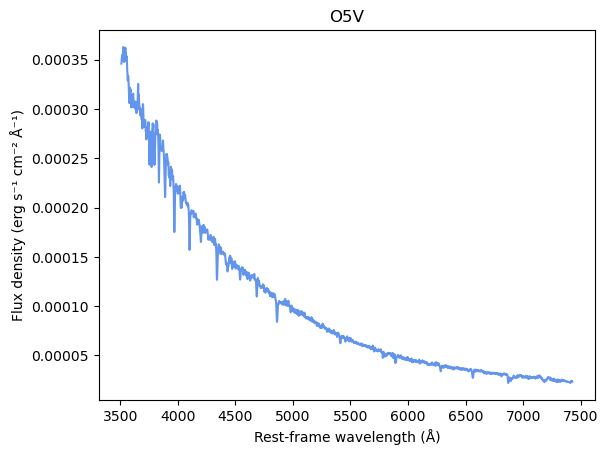

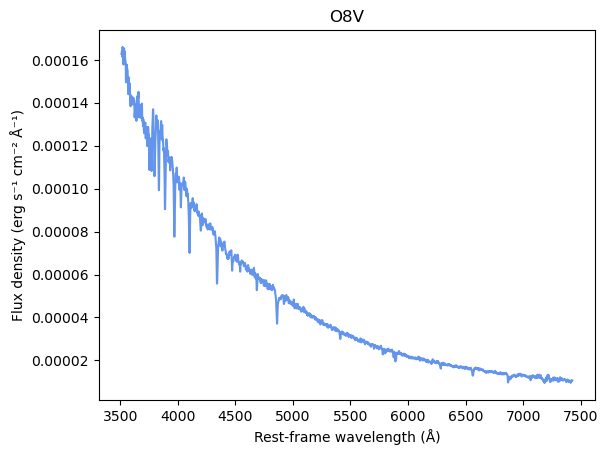

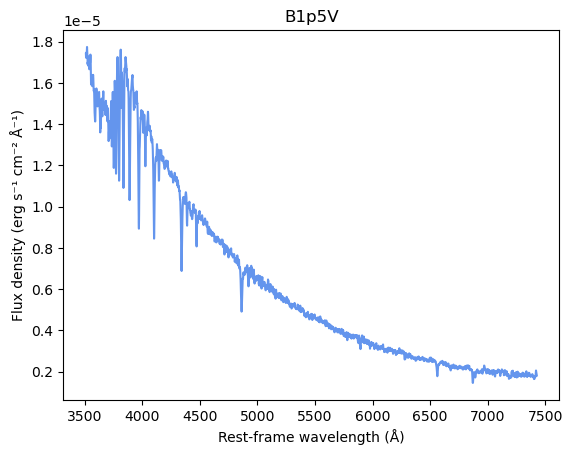

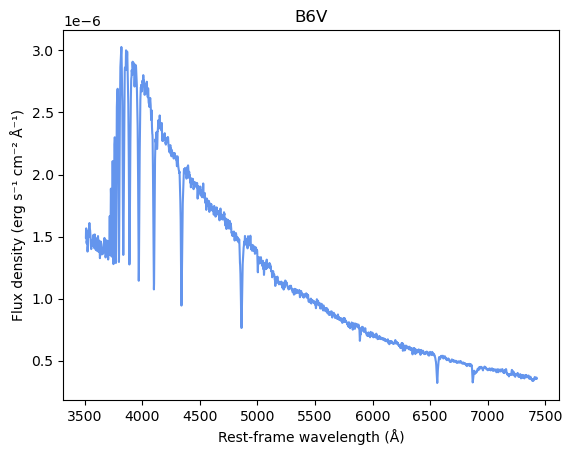

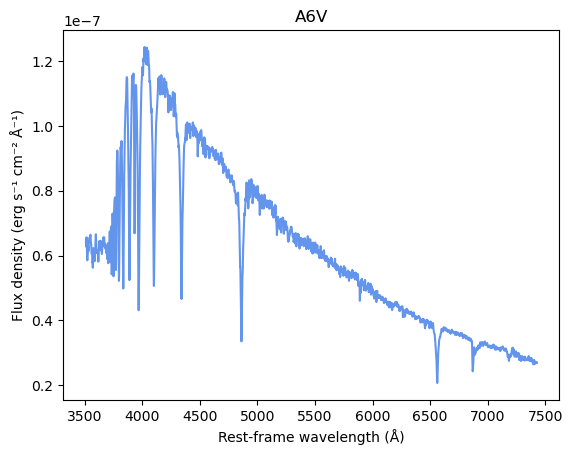

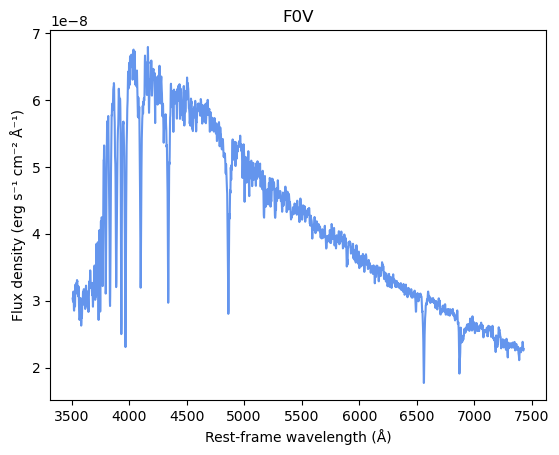

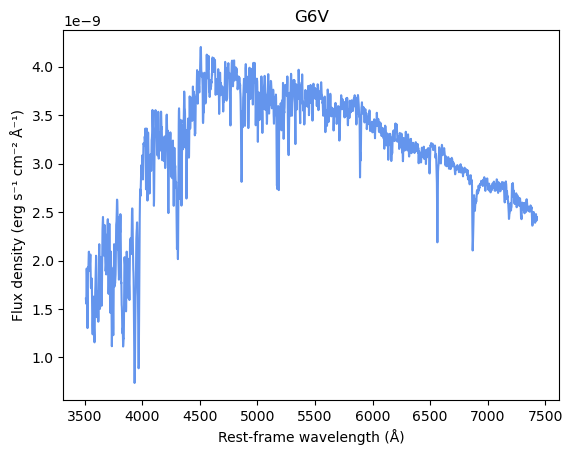

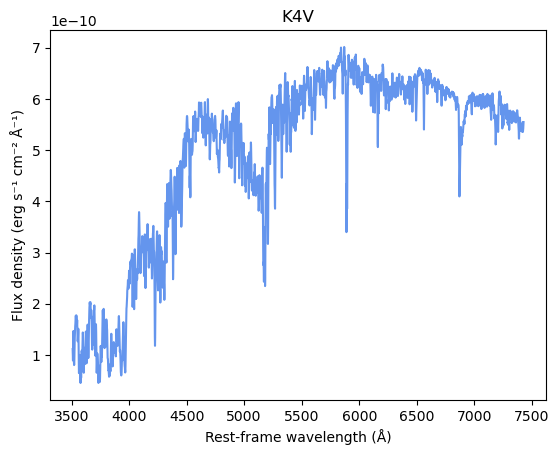

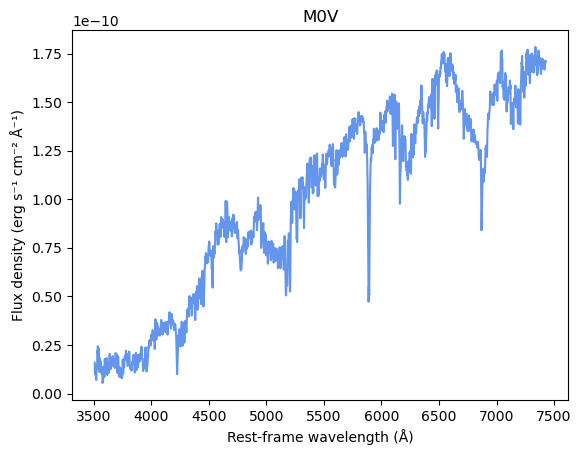

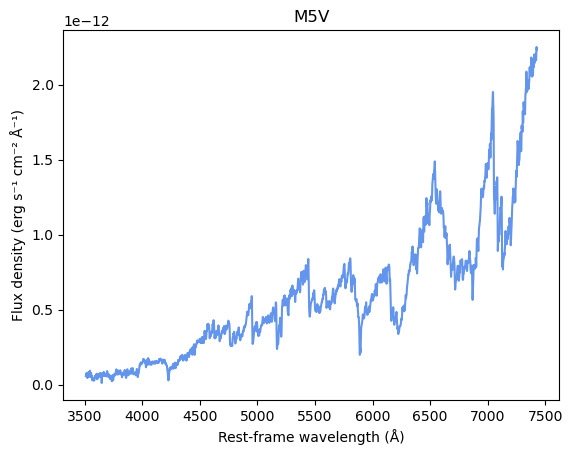

In [11]:
for star, spectrum in spectra.items():
    spectrum.plot(x="wavelength", y="flux", color="cornflowerblue", title=star, xlabel="Rest-frame wavelength (Å)",
        ylabel="Flux density (erg s⁻¹ cm⁻² Å⁻¹)",
        legend=False)

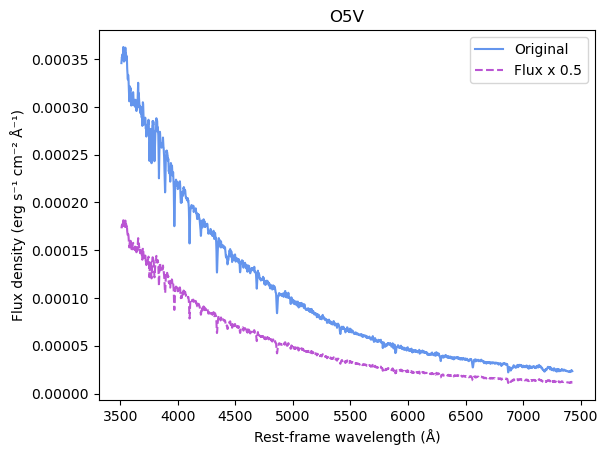

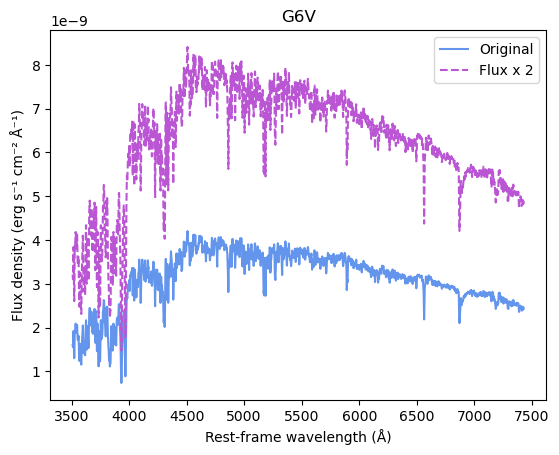

In [14]:
scale_factors = {"O5V": 0.5, "G6V": 2}

for star, factor in scale_factors.items():
    spectrum = spectra[star].assign(scaled_flux = spectra[star]["flux"] * factor)

    ax = spectrum.plot(x = "wavelength", y = "flux", color = "cornflowerblue", label = "Original", title = star)

    spectrum.plot(x = "wavelength", y = "scaled_flux", ax = ax, color = "mediumorchid", linestyle = "--", label = f"Flux x {factor}")

    ax.set_xlabel("Rest-frame wavelength (Å)")
    ax.set_ylabel("Flux density (erg s⁻¹ cm⁻² Å⁻¹)")

<Axes: title={'center': 'O5V / G6V'}, xlabel='Rest-frame wavelength (Å)', ylabel='Flux density ratio'>

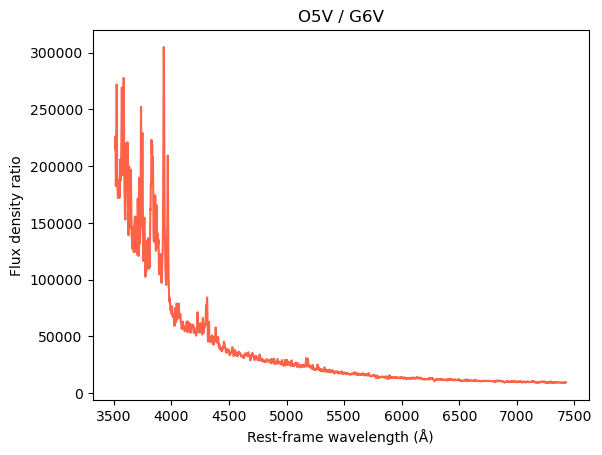

In [ ]:
paired = spectra["O5V"].merge(spectra["G6V"], on="wavelength", suffixes=("_O5V", "_G6V"))

paired["ratio"] = paired["flux_O5V"].div(paired["flux_G6V"].where(paired["flux_G6V"].ne(0)))

paired.plot(x = "wavelength", y = "ratio", color = "tomato", title = "O5V / G6V",
    xlabel="Rest-frame wavelength (Å)",
    ylabel="Flux density ratio",
    legend=False)

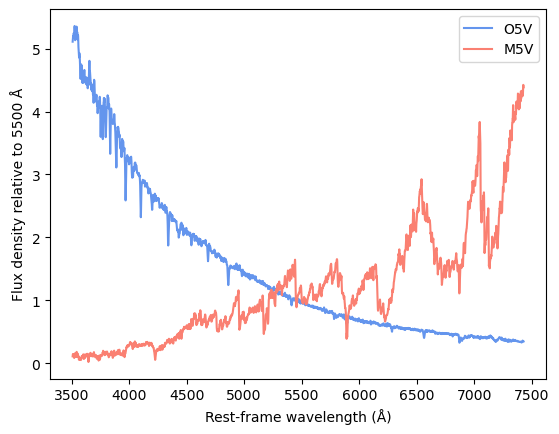

In [ ]:
ax = None

for star, color in [("O5V", "cornflowerblue"), ("M5V", "salmon")]:
    spectrum = spectra[star]
    reference_row = (spectrum["wavelength"] - 5500).abs().idxmin()
    reference_flux = spectrum.loc[reference_row, "flux"]

    ax = spectrum.assign(relative_flux = spectrum["flux"] / reference_flux).plot(x = "wavelength", y = "relative_flux", ax = ax, color = color, label = star, xlabel = "Rest-frame wavelength (Å)", ylabel = "Flux density relative to 5500 Å")

## PART 2 A

In [37]:
m_counts = {"M0V": 70, "M5V": 130}
k_counts = {"K4V": 25}
afg_counts = {"A6V": 4, "F0V": 8, "G6V": 13}
b_counts = {"B1p5V": 3, "B6V": 7}
o_counts = {"O5V": 0.3, "O8V": 0.7}

In [38]:
def composite_spectrum(star_counts):
    # Align the templates by wavelength and weight each by its star count.
    contributions = pd.concat([
            spectra[star].set_index("wavelength")["flux"] * count
            for star, count in star_counts.items()],axis=1, join="inner")

    # Add the flux densities across templates at each wavelength.
    return contributions.sum(axis=1).sort_index()

box1 = composite_spectrum(m_counts)
box2 = composite_spectrum(k_counts)
box3 = composite_spectrum(afg_counts)
box4 = composite_spectrum(b_counts)
box5 = composite_spectrum(o_counts)

boxes = pd.concat({"M": box1, "K": box2, "A/F/G": box3, "B": box4, "O": box5}, axis=1, join="inner")
composite = boxes.sum(axis=1).rename("Composite")

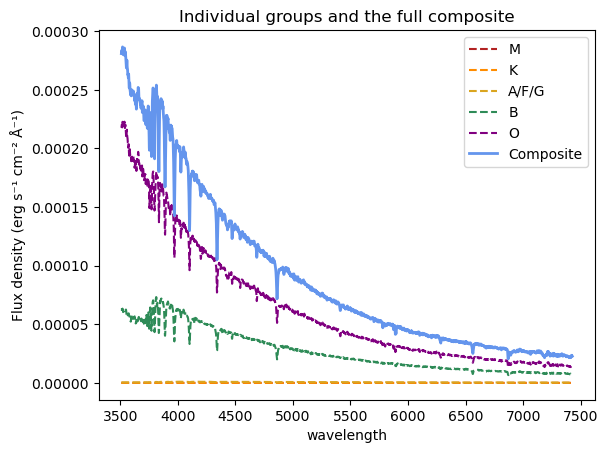

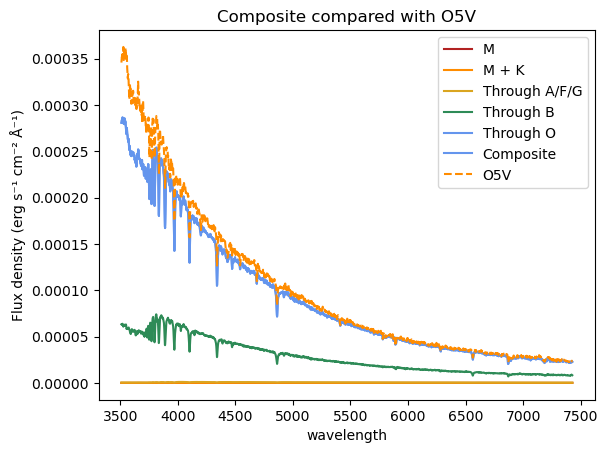

In [39]:
xlabel = "Rest-frame wavelength (Å)"
ylabel = "Flux density (erg s⁻¹ cm⁻² Å⁻¹)"
colors = ["firebrick", "darkorange", "goldenrod", "seagreen", "purple"]

# Show what each group contributes to the full spectrum.
ax = boxes.plot(color = colors, linestyle = "--", title = "Individual groups and the full composite", xlabel = xlabel, ylabel = ylabel)
composite.plot(ax = ax, color = "cornflowerblue", linewidth = 2)
ax.legend()

# Add the groups in order from least to most massive.
cumulative = boxes.cumsum(axis = "columns")
cumulative.columns = ["M", "M + K", "Through A/F/G", "Through B", "Through O"]
cumulative.plot(color=colors[:4] + ["cornflowerblue"], title = "Building the composite", xlabel = xlabel, ylabel = ylabel)

# Compare the full composite with the most massive template.
ax = composite.plot(color = "cornflowerblue", title = "Composite compared with O5V", xlabel = xlabel, ylabel = ylabel,)
spectra["O5V"].set_index("wavelength")["flux"].plot(ax = ax, color = "darkorange", linestyle = "--", label = "O5V")
ax.legend()